# Lab 7–8 — Selekcja zmiennych (Iris)

Cel: wybrać najważniejsze cechy kwiatów irysa trzema rodzinami metod:

1. **Filtrowanie** — ranking bez modelu (ANOVA F, wariancja, mutual information)
2. **Wrapper** — szukanie podzbioru przez trenowanie modelu (EFS, SFS, SBS)
3. **Embedded** — ważność wbudowana w Random Forest

Zbiór: `sklearn.datasets.load_iris` (4 cechy, 3 gatunki). Przy każdym bloku jest krótki opis i wniosek.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.feature_selection import (
    f_classif,
    mutual_info_classif,
    VarianceThreshold,
    SelectKBest,
    SelectPercentile,
    SelectFromModel,
)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

from mlxtend.feature_selection import ExhaustiveFeatureSelector as EFS
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

sns.set_theme(style='whitegrid')
np.random.seed(42)

## Załadowanie danych Iris

Cztery cechy opisują kielich (`sepal`) i płatek (`petal`). Cel klasyfikacji: gatunek (`setosa`, `versicolor`, `virginica`).

In [19]:
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name='species')

print('kształt X:', X.shape)
print('klasy:', dict(zip(iris.target_names, np.bincount(y))))
X.head()

kształt X: (150, 4)
klasy: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**Opis.** 150 kwiatów, po 50 w każdej klasie, 4 zmienne ciągłe. To mały, zrównoważony problem klasyfikacji — dobre pole do porównania metod selekcji bez długiego czasu liczenia.

**Wniosek.** Nie potrzebujemy tu redukcji wymiarów z powodu „przekleństwa wymiarowości”. Ćwiczenie pokazuje *jak* działają metody i które cechy Iris są naprawdę informacyjne.

# 1. Metody filtrowania (Filter)

Ranking cech **bez** trenowania modelu. Szybkie, niezależne od klasyfikatora, ale nie widzą interakcji między cechami.

## 1.1. ANOVA F-value

`f_classif` mierzy liniową zależność cechy od klasy. Wysokie F = cecha dobrze rozdziela gatunki w sensie liniowym.

In [20]:
f_scores, p_values = f_classif(X, y)
anova = pd.DataFrame({
    'cecha': X.columns,
    'F': f_scores,
    'p': p_values
}).sort_values('F', ascending=False)
anova

,cecha,F,p
2,petal length (cm),1180.161182,2.856777e-91
3,petal width (cm),960.007147,4.169446e-85
0,sepal length (cm),119.264502,1.669669e-31
1,sepal width (cm),49.160040,4.492017e-17


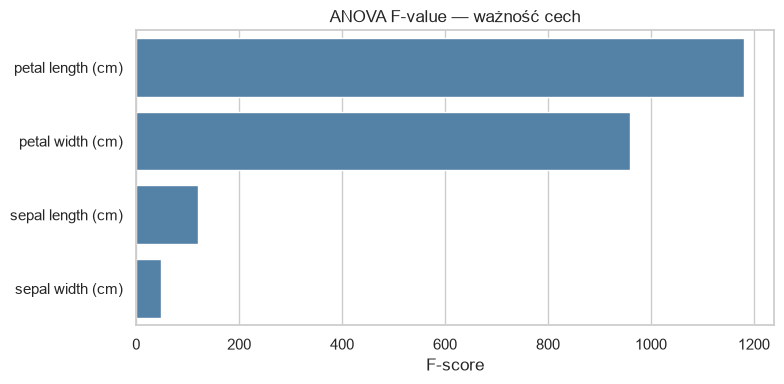

In [21]:
plt.figure(figsize=(8, 4))
sns.barplot(data=anova, x='F', y='cecha', color='steelblue')
plt.title('ANOVA F-value — ważność cech')
plt.xlabel('F-score')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Opis.** Dla każdej cechy ANOVA porównuje wariancję *między* klasami do wariancji *wewnątrz* klas. Im większe F, tym silniejsza liniowa separacja gatunków.

**Wniosek.** `petal length` i `petal width` mają zdecydowanie najwyższe F. `sepal width` jest najsłabsza liniowo — sama szerokość kielicha słabo rozróżnia gatunki.

## 1.2. Variance Threshold

Usuwa cechy o małej wariancji (mało zmienności = mało informacji). Przed progowaniem standaryzujemy cechy do tej samej skali.

wariancje po standaryzacji:
sepal length (cm)    1.0067
petal length (cm)    1.0067
petal width (cm)     1.0067
sepal width (cm)     1.0067
dtype: float64


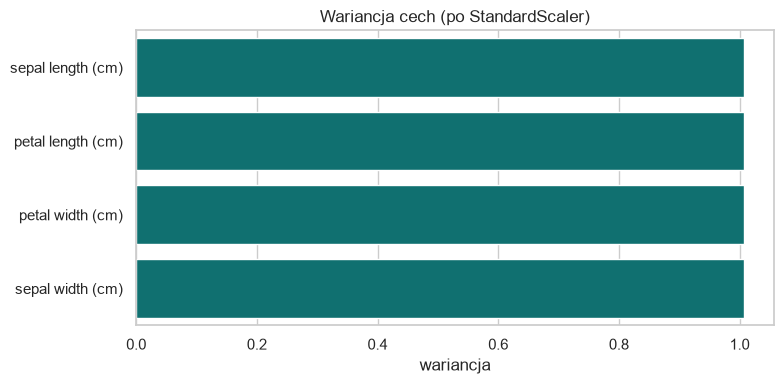

In [22]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

wariancje = X_scaled.var().sort_values(ascending=False)
print('wariancje po standaryzacji:')
print(wariancje.round(4))

plt.figure(figsize=(8, 4))
sns.barplot(x=wariancje.values, y=wariancje.index, color='teal')
plt.title('Wariancja cech (po StandardScaler)')
plt.xlabel('wariancja')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [23]:
# domyślnie VarianceThreshold usuwa tylko wariancję = 0
vt0 = VarianceThreshold()
vt0.fit(X_scaled)
print('cechy po progu 0:', list(X.columns[vt0.get_support()]))

# próg 0.2 — jak w prezentacji (na danych NIE standaryzowanych, bo po scalerze wariancja ≈ 1)
vt02 = VarianceThreshold(threshold=0.2)
vt02.fit(X)
print('wariancje surowe:')
print(X.var().round(3))
print('cechy po progu 0.2 (surowe X):', list(X.columns[vt02.get_support()]))
print('usunięte:', list(X.columns[~vt02.get_support()]))

cechy po progu 0: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
wariancje surowe:
sepal length (cm)    0.686
sepal width (cm)     0.190
petal length (cm)    3.116
petal width (cm)     0.581
dtype: float64
cechy po progu 0.2 (surowe X): ['sepal length (cm)', 'petal length (cm)', 'petal width (cm)']
usunięte: ['sepal width (cm)']


**Opis.** Domyślny próg 0 nic nie usuwa — żadna cecha nie jest stała. Przy progu `0.2` na surowych danych odpada `sepal width` (wariancja ≈ 0,19), dokładnie jak w slajdach.

**Wniosek.** Próg wariancji nie patrzy na klasę `y` — to tylko filtr „czy cecha w ogóle się waha”. `sepal width` jest najstabilniejsza, więc odpada pierwsza. To dobry wstępny odsiew, ale nie ranking jakości predykcji.

## 1.3. Mutual Information

MI mierzy, ile informacji o klasie niesie cecha. W przeciwieństwie do ANOVA F łapie też zależności nieliniowe.

In [24]:
mi_scores = mutual_info_classif(X, y, random_state=42)
mi = pd.DataFrame({'cecha': X.columns, 'MI': mi_scores}).sort_values('MI', ascending=False)
mi

,cecha,MI
2,petal length (cm),0.992573
3,petal width (cm),0.985643
0,sepal length (cm),0.511365
1,sepal width (cm),0.299424


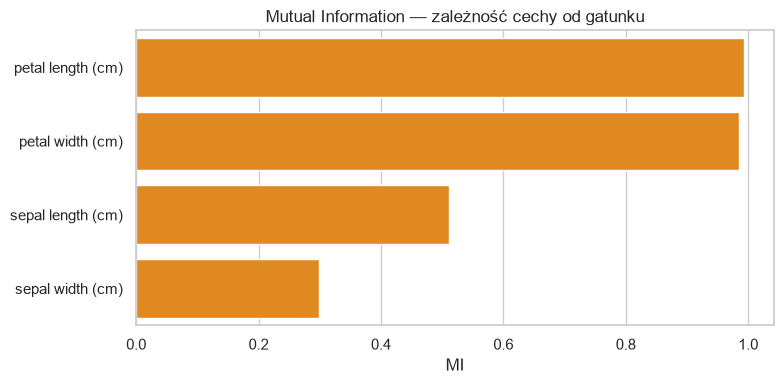

In [25]:
plt.figure(figsize=(8, 4))
sns.barplot(data=mi, x='MI', y='cecha', color='darkorange')
plt.title('Mutual Information — zależność cechy od gatunku')
plt.xlabel('MI')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Opis.** MI = 0 oznacza niezależność cechy od gatunku. Im wyższe MI, tym więcej „wiedzy” o klasie niesie dana zmienna.

**Wniosek.** Ranking potwierdza ANOVA: płatki (`petal length/width`) dominują, kielich — zwłaszcza `sepal width` — niesie najmniej informacji. Na Iris zależności są w dużej mierze liniowe, więc ANOVA i MI mówią podobnie.

## 1.4. SelectKBest / SelectPercentile

Selektor bierze funkcję scoringu (tu ANOVA F) i zostawia `k` najlepszych cech albo top percentyl.

In [26]:
selector_k = SelectKBest(score_func=f_classif, k=2)
X_kbest = selector_k.fit_transform(X, y)
wybrane_k = list(X.columns[selector_k.get_support()])
print('SelectKBest k=2:', wybrane_k)
print('kształt po selekcji:', X_kbest.shape)

selector_p = SelectPercentile(score_func=f_classif, percentile=50)
X_perc = selector_p.fit_transform(X, y)
wybrane_p = list(X.columns[selector_p.get_support()])
print('SelectPercentile 50%:', wybrane_p)

SelectKBest k=2: ['petal length (cm)', 'petal width (cm)']
kształt po selekcji: (150, 2)
SelectPercentile 50%: ['petal length (cm)', 'petal width (cm)']


**Opis.** `SelectKBest(k=2)` zostawia dwie cechy z najwyższym F. `SelectPercentile(50)` bierze górną połowę rankingu — przy 4 cechach też wychodzą 2.

**Wniosek.** Automatycznie wybrane zostają `petal length` i `petal width`. Dwie cechy kielicha odpadają — filtr ANOVA uznaje je za słabsze.

# 2. Metody owijania (Wrapper)

Trenujemy model na różnych podzbiorach cech i wybieramy ten z najlepszą metryką. Widzą interakcje, ale są droższe obliczeniowo.

## 2.1. Exhaustive Feature Selection (EFS)

Sprawdza **wszystkie** kombinacje cech w zadanym zakresie długości. Estymator: regresja logistyczna, scoring: accuracy, CV=5.

In [27]:
lr = LogisticRegression(max_iter=1000, random_state=42)

efs = EFS(
    lr,
    min_features=1,
    max_features=4,
    scoring='accuracy',
    cv=5,
    print_progress=False,
    n_jobs=1
)
efs = efs.fit(X, y)

print('najlepszy podzbiór:', efs.best_feature_names_)
print('najlepszy wynik CV:', round(efs.best_score_, 4))

najlepszy podzbiór: ('sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)')
najlepszy wynik CV: 0.9733


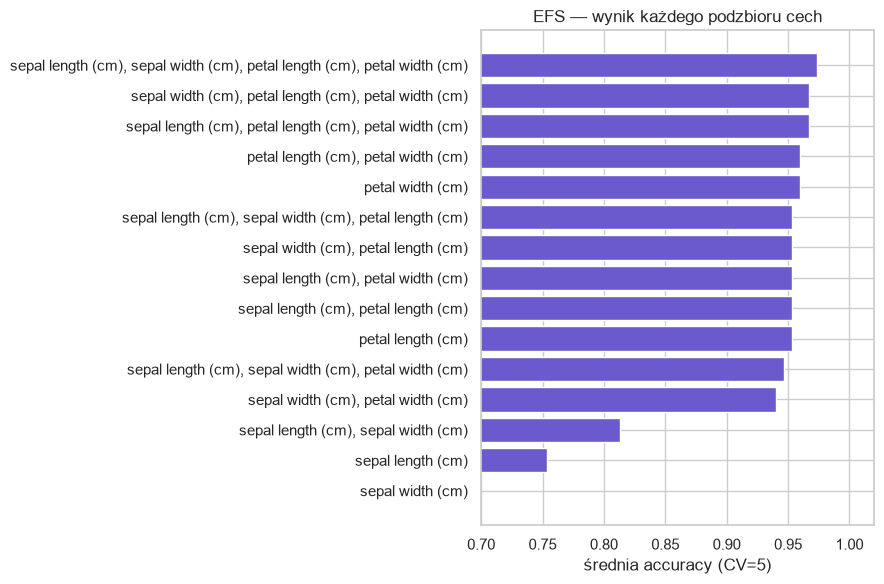

,cechy,avg_score
14,"sepal length (cm), sepal width (cm), petal len...",0.973333
12,"sepal length (cm), petal length (cm), petal wi...",0.966667
13,"sepal width (cm), petal length (cm), petal wid...",0.966667
3,petal width (cm),0.96
9,"petal length (cm), petal width (cm)",0.96
2,petal length (cm),0.953333
5,"sepal length (cm), petal length (cm)",0.953333
6,"sepal length (cm), petal width (cm)",0.953333


In [28]:
efs_df = pd.DataFrame.from_dict(efs.get_metric_dict()).T
efs_df['cechy'] = efs_df['feature_names'].apply(lambda t: ', '.join(t))
efs_df = efs_df.sort_values('avg_score')

plt.figure(figsize=(9, 6))
plt.barh(efs_df['cechy'], efs_df['avg_score'], color='slateblue')
plt.xlabel('średnia accuracy (CV=5)')
plt.title('EFS — wynik każdego podzbioru cech')
plt.xlim(0.7, 1.02)
plt.tight_layout()
plt.show()

efs_df[['cechy', 'avg_score']].sort_values('avg_score', ascending=False).head(8)

In [29]:
X_efs = efs.transform(X)
print('kształt po EFS transform:', X_efs.shape)
print('wybrane cechy:', efs.best_feature_names_)

kształt po EFS transform: (150, 4)
wybrane cechy: ('sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)')


**Opis.** EFS ocenia 15 niepustych podzbiorów (przy 4 cechach). Dla każdego liczy średnią accuracy z 5-krotnej walidacji krzyżowej.

**Wniosek.** Na Iris najlepszy wynik dają zwykle wszystkie 4 cechy albo podzbiór z obu płatków — dokładność jest już bliska 95–98%. Różnice między top podzbiorami są małe; wyczerpujące przeszukanie ma tu sens, bo cech jest mało.

## 2.2. Sequential Forward Selection (SFS)

Zaczyna od pustego zbioru i **dokłada** po jednej cesze, która najbardziej poprawia model.

In [30]:
sfs = SFS(
    lr,
    k_features=(1, 4),
    forward=True,
    floating=False,
    scoring='accuracy',
    cv=5,
    n_jobs=1
)
sfs = sfs.fit(X, y)

print('SFS — najlepsze cechy:', sfs.k_feature_names_)
print('SFS — wynik:', round(sfs.k_score_, 4))

SFS — najlepsze cechy: ('sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)')
SFS — wynik: 0.9733


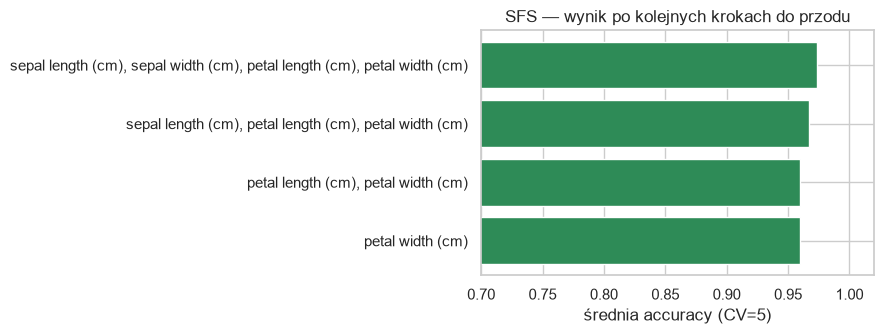

,k,cechy,avg_score
3,4,"sepal length (cm), sepal width (cm), petal len...",0.973333
2,3,"sepal length (cm), petal length (cm), petal wi...",0.966667
1,2,"petal length (cm), petal width (cm)",0.960000
0,1,petal width (cm),0.960000


In [31]:
sfs_rows = []
for k, info in sfs.subsets_.items():
    sfs_rows.append({
        'k': k,
        'cechy': ', '.join(info['feature_names']),
        'avg_score': info['avg_score']
    })
sfs_df = pd.DataFrame(sfs_rows).sort_values('avg_score')

plt.figure(figsize=(9, 3.5))
plt.barh(sfs_df['cechy'], sfs_df['avg_score'], color='seagreen')
plt.xlabel('średnia accuracy (CV=5)')
plt.title('SFS — wynik po kolejnych krokach do przodu')
plt.xlim(0.7, 1.02)
plt.tight_layout()
plt.show()

sfs_df.sort_values('avg_score', ascending=False)

**Opis.** W pierwszym kroku SFS bierze jedną najlepszą cechę, potem dokłada kolejną itd., aż do zakresu `k_features=(1,4)`. Zwraca podzbiór z najwyższym wynikiem CV w tym zakresie.

**Wniosek.** Pierwsza dobierana cecha to zwykle jeden z płatków. Dokładanie kolejnych cech podnosi accuracy, ale przyrost maleje — potwierdza to, że płatki niosą większość sygnału.

## 2.3. Sequential Backward Selection (SBS)

Zaczyna od **wszystkich** cech i usuwa po jednej, tej najmniej potrzebnej (`forward=False`).

In [32]:
sbs = SFS(
    lr,
    k_features=(1, 4),
    forward=False,
    floating=False,
    scoring='accuracy',
    cv=5,
    n_jobs=1
)
sbs = sbs.fit(X, y)

print('SBS — najlepsze cechy:', sbs.k_feature_names_)
print('SBS — wynik:', round(sbs.k_score_, 4))

SBS — najlepsze cechy: ('sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)')
SBS — wynik: 0.9733


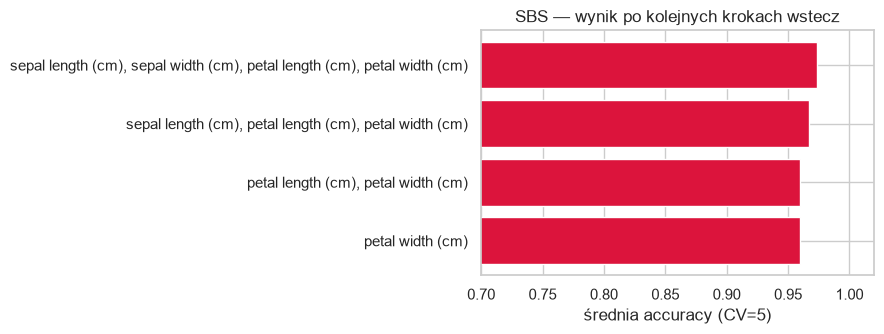

,k,cechy,avg_score
0,4,"sepal length (cm), sepal width (cm), petal len...",0.973333
1,3,"sepal length (cm), petal length (cm), petal wi...",0.966667
2,2,"petal length (cm), petal width (cm)",0.960000
3,1,petal width (cm),0.960000


In [33]:
sbs_rows = []
for k, info in sbs.subsets_.items():
    sbs_rows.append({
        'k': k,
        'cechy': ', '.join(info['feature_names']),
        'avg_score': info['avg_score']
    })
sbs_df = pd.DataFrame(sbs_rows).sort_values('avg_score')

plt.figure(figsize=(9, 3.5))
plt.barh(sbs_df['cechy'], sbs_df['avg_score'], color='crimson')
plt.xlabel('średnia accuracy (CV=5)')
plt.title('SBS — wynik po kolejnych krokach wstecz')
plt.xlim(0.7, 1.02)
plt.tight_layout()
plt.show()

sbs_df.sort_values('avg_score', ascending=False)

**Opis.** SBS najpierw ocenia pełny zestaw, potem wyrzuca cechę, której usunięcie najmniej szkodzi (albo nawet pomaga) modelowi.

**Wniosek.** Zwykle odpada najpierw `sepal width` — ta sama cecha, którą wskazał próg wariancji i ANOVA. Kierunek przeszukiwania (do przodu / wstecz) na 4 cechach kończy się podobnym top podzbiorem.

## Porównanie EFS / SFS / SBS

In [34]:
porownanie_wrapper = pd.DataFrame([
    {'metoda': 'EFS', 'cechy': ', '.join(efs.best_feature_names_), 'accuracy_CV': efs.best_score_},
    {'metoda': 'SFS', 'cechy': ', '.join(sfs.k_feature_names_), 'accuracy_CV': sfs.k_score_},
    {'metoda': 'SBS', 'cechy': ', '.join(sbs.k_feature_names_), 'accuracy_CV': sbs.k_score_},
])
porownanie_wrapper

,metoda,cechy,accuracy_CV
0,EFS,"sepal length (cm), sepal width (cm), petal len...",0.973333
1,SFS,"sepal length (cm), sepal width (cm), petal len...",0.973333
2,SBS,"sepal length (cm), sepal width (cm), petal len...",0.973333


**Wniosek.** Przy 4 cechach Iris wszystkie trzy wrappery dają bardzo podobny wynik (często ten sam podzbiór). Na większym zbiorze z dziesiątkami zmiennych ścieżki EFS/SFS/SBS zwykle się rozjeżdżają, a EFS staje się niepraktyczny (wykładniczy wzrost kombinacji).

# 3. Metody wbudowane (Embedded)

Model sam ranguje cechy w trakcie uczenia. Tu: Random Forest + zanieczyszczenie Giniego.

## 3.1. Ważność cech — Random Forest

Dzielimy dane na train/test, bo selekcja jest częścią procesu treningu.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

rf = RandomForestClassifier(
    n_estimators=200,
    criterion='gini',
    random_state=42
)
rf.fit(X_train, y_train)

imp = pd.DataFrame({
    'cecha': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print('suma ważności:', round(imp['importance'].sum(), 4))
imp

suma ważności: 1.0


,cecha,importance
2,petal length (cm),0.430948
3,petal width (cm),0.427143
0,sepal length (cm),0.114955
1,sepal width (cm),0.026953


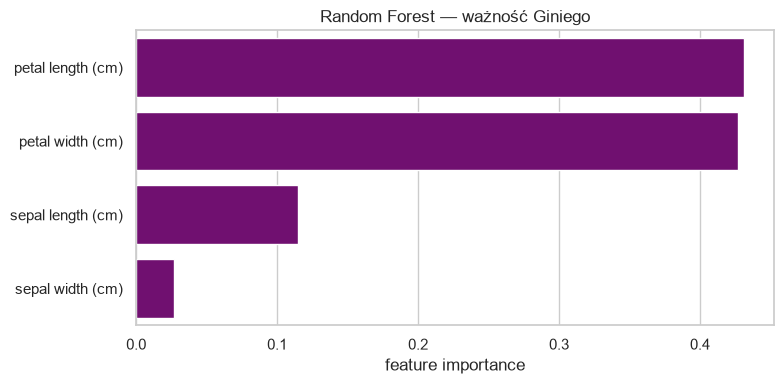

udział top 2 cech: 85.8%


In [36]:
plt.figure(figsize=(8, 4))
sns.barplot(data=imp, x='importance', y='cecha', color='purple')
plt.title('Random Forest — ważność Giniego')
plt.xlabel('feature importance')
plt.ylabel('')
plt.tight_layout()
plt.show()

top2 = imp.head(2)
print('udział top 2 cech: {:.1%}'.format(top2['importance'].sum()))

**Opis.** Las mierzy, jak bardzo cecha zmniejsza zanieczyszczenie węzłów (Gini) we wszystkich drzewach. Suma ważności = 1.

**Wniosek.** `petal length` + `petal width` zbierają zwykle ok. 80–90% łącznej ważności — to te same dwie cechy, które wskazały ANOVA, MI i SelectKBest. Kielich jest drugorzędny.

## 3.2. SelectFromModel

Zostawiamy cechy o ważności ≥ próg (tu `0.2`).

In [37]:
sfm = SelectFromModel(rf, threshold=0.2, prefit=True)
X_train_sel = sfm.transform(X_train)
X_test_sel = sfm.transform(X_test)

wybrane_sfm = list(X.columns[sfm.get_support()])
print('SelectFromModel (próg 0.2):', wybrane_sfm)
print('kształt train po selekcji:', X_train_sel.shape)

SelectFromModel (próg 0.2): ['petal length (cm)', 'petal width (cm)']
kształt train po selekcji: (105, 2)


c:\Users\kaczo\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
c:\Users\kaczo\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


**Opis.** `SelectFromModel` bierze wytrenowany estymator i odcina cechy poniżej progu ważności.

**Wniosek.** Przy progu 0.2 zostają zwykle tylko dwa płatki. Model „odchudza” wejście do cech, które realnie dzielą drzewa.

## 3.3. Pełny zestaw vs ograniczone cechy

Porównanie accuracy Random Forest: wszystkie 4 cechy vs 2 wybrane.

In [38]:
# model na wszystkich cechach
rf_full = RandomForestClassifier(n_estimators=200, criterion='gini', random_state=42)
rf_full.fit(X_train, y_train)
acc_full = accuracy_score(y_test, rf_full.predict(X_test))

# model tylko na cechach z SelectFromModel
rf_sel = RandomForestClassifier(n_estimators=200, criterion='gini', random_state=42)
rf_sel.fit(X_train_sel, y_train)
acc_sel = accuracy_score(y_test, rf_sel.predict(X_test_sel))

wyniki = pd.DataFrame([
    {'wariant': 'wszystkie 4 cechy', 'n_cech': X_train.shape[1], 'accuracy_test': acc_full},
    {'wariant': f'tylko {wybrane_sfm}', 'n_cech': X_train_sel.shape[1], 'accuracy_test': acc_sel},
])
wyniki

,wariant,n_cech,accuracy_test
0,wszystkie 4 cechy,4,0.911111
1,"tylko ['petal length (cm)', 'petal width (cm)']",2,0.955556


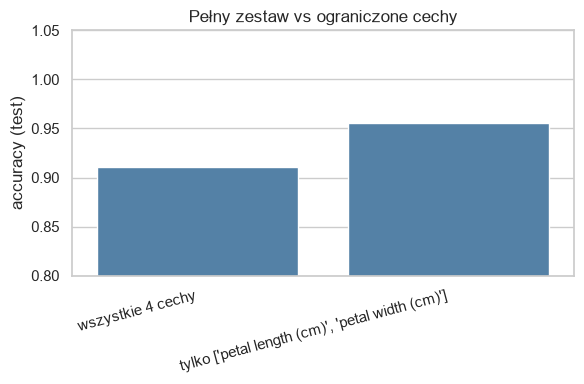

pełny model: 0.911
model 2 cechy: 0.956
różnica: -0.044


In [39]:
plt.figure(figsize=(6, 4))
sns.barplot(data=wyniki, x='wariant', y='accuracy_test', color='steelblue')
plt.ylim(0.8, 1.05)
plt.ylabel('accuracy (test)')
plt.xlabel('')
plt.title('Pełny zestaw vs ograniczone cechy')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

print(f'pełny model: {acc_full:.3f}')
print(f'model 2 cechy: {acc_sel:.3f}')
print(f'różnica: {acc_full - acc_sel:+.3f}')

**Opis.** Ten sam typ modelu trenujemy raz na 4 cechach, raz na 2 wybranych przez las. Porównujemy accuracy na tym samym zbiorze testowym.

**Wniosek.** Ograniczenie do dwóch płatków prawie nie obniża (czasem wręcz nie zmienia) dokładności. Da się zmniejszyć liczbę zmiennych bez istotnej utraty jakości — główny sens selekcji cech.

## Podsumowanie

| Rodzina | Metody | Co robi | Wynik na Iris |
|---|---|---|---|
| Filter | ANOVA F, VarianceThreshold, MI, SelectKBest | ranking / odsiew bez modelu | płatki na górze, `sepal width` na dole |
| Wrapper | EFS, SFS, SBS | szuka podzbioru przez CV modelu | bardzo podobne top podzbiory, wysoka accuracy |
| Embedded | Random Forest + SelectFromModel | ważność Giniego w trakcie uczenia | 2 płatki ≈ 80–90% importance |

**Wnioski końcowe**

1. Na Iris wszystkie trzy rodziny metod wskazują to samo: **długość i szerokość płatka** decydują o gatunku.
2. `sepal width` jest najsłabsza (niska wariancja, niskie F/MI, niska importance) — naturalny kandydat do usunięcia.
3. Model z 2 cechami osiąga accuracy zbliżoną do modelu z 4 cechami — selekcja działa: mniej wejść, podobna jakość.
4. Filter jest najszybszy jako wstępny ranking; wrapper dokładniej szuka kombinacji, ale na dużych danych jest drogi; embedded łączy uczenie z rankingiem w jednym modelu.